**23 | Unified Matched Benchmark: Seven HARTH Activity Classifiers**

![Stage 23 horizontal scientific workflow](../images/23_workflow.svg)

**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**Research aim:** Compare Random Forest, Standard CNN, Weighted CNN, TCN, Multi-Scale CNN, 1D-ResNet and Time-Series Transformer in one source-row- and participant-matched eight-class development experiment. All classifiers use precisely the same subject-held-out GroupKFold Validation windows. This is an **exploratory development benchmark**, not independent Test generalisation or evidence of a clinically validated activity recognition system.

**Resumability:** Each model/fold job saves original source-row IDs, true labels, predictions, hyperparameters, architecture-source fingerprint and timing in an ignored local JSON file. Interrupted training can resume by rerunning the training cell. Results are not displayed as complete until every expected job passes source-alignment validation. **Only actual executed notebook outputs**, not local cache or untrained model results, are pushed to GitHub.

**01. Scientific Question, Model Families and Evaluation Boundary**

We ask whether the four temporal architectures from Stage 22 outperform the existing RF and simple CNN baselines on the *same* bounded HARTH development data. The predefined target codes are `1–8`; cycling and undocumented labels are removed **after** time-safe window formation. The dataset contains 29 Development participants. Original Test subjects S023/S032 were inspected early in the project but are excluded from all subsequent training, selection and scoring.

**Important comparability distinctions:** RF receives 30 deterministic statistical features extracted from the identical raw source windows, whereas neural models receive all 6×100 source samples. Neural networks share 400 Optimiser Steps, Adam, batch size, learning rate, source windows and folds; Random Forest uses its established 120-tree configuration. Fixed Steps do *not* equalise FLOPs, parameter counts, data exposure, training convergence or runtime. Models are evaluated using fixed-eight-class Macro F1 rather than overall accuracy alone.

**Protocol distinction:** Random Forest uses 30 deterministic window features; all neural models use the original six-channel time series. Equal updates do not equalise model capacity, convergence or computation.

In [2]:
# ================== 01. Imports and Fixed Research Protocol ==================

# --------------- 1. Import the Python data and path utilities ---------------
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -------------- 2. Load PyTorch for six temporal neural models --------------
import torch
from IPython.display import display

# ------------ 3. Resolve and register repository module locations ------------
root=Path.cwd().resolve()
while not (root/"code/python/src/core/data_loading.py").is_file():
    if root==root.parent: raise RuntimeError("Open notebook inside the repository.")
    root=root.parent
sys.path.insert(0,str(root/"code/python/src"))
sys.path.insert(0,str(root/"studies/wearable_activity_recognition/src"))

# ------------ 4. Import pinned HARTH source and task definitions ------------
from harth_data import (
    HARTH_SUBJECTS, HARTH_REVISION, SENSOR_COLUMNS, ACTIVITY_NAMES,
    prepare_harth_window_cohort
)

# ------------ 5. Import fingerprinted model evaluation functions ------------
from core.temporal_benchmark import (
    MODEL_NAMES, PROTOCOL_VERSION, make_benchmark_plan,
    run_benchmark_job, summarise_benchmark_results
)
from core.feature_engineering import extract_signal_features

# ------------ 6. Keep original Test subjects outside Development ------------
RESERVED_TEST={"S023","S032"}
DEVELOPMENT_SUBJECTS=sorted(set(HARTH_SUBJECTS)-RESERVED_TEST)
CLASSES=tuple(range(1,9))

# ----------- 7. Fix three independent-participant validation folds -----------
FOLDS=3
MAX_WINDOWS_PER_SUBJECT=500

# ---------------- 8. Set equal neural optimiser-step budgets ----------------
MAX_STEPS=400
BATCH_SIZE=128
SEED=42

# ------------- 9. Preserve the original CUDA-required experiment -------------
REQUIRE_CUDA = True
if REQUIRE_CUDA and not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA GPU is unavailable. In Google Colab select Runtime > "
        "Change runtime type > Hardware accelerator > GPU, then reconnect."
    )
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# ------------ 10. Apply original full-precision GPU configuration ------------
if DEVICE == "cuda":
    torch.set_float32_matmul_precision("highest")
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
    gpu_properties = torch.cuda.get_device_properties(0)
    GPU_NAME = torch.cuda.get_device_name(0)
    GPU_MEMORY_GB = round(gpu_properties.total_memory / 1024**3, 2)
else:
    GPU_NAME = "No CUDA GPU"
    GPU_MEMORY_GB = 0.0

# ---------- 11. Record the original resumable prediction-cache path ----------
CACHE_DIR=root/"data/processed/harth_stage23_matched_benchmark"

# ----------- 12. Verify 29 people and all seven configured models -----------
assert len(DEVELOPMENT_SUBJECTS)==29 and not(set(DEVELOPMENT_SUBJECTS)&RESERVED_TEST)
assert len(MODEL_NAMES)==7

print(""+"="*70)

# ------------ 13. Report the fixed training protocol and hardware ------------
print("STAGE 23 | SEVEN-MODEL MATCHED DEVELOPMENT BENCHMARK")
print("="*70)
print("Pinned official HARTH revision:",HARTH_REVISION)
print("Device:",DEVICE,"| PyTorch:",torch.__version__)
print("GPU:",GPU_NAME,"| Visible GPU memory (GiB):",GPU_MEMORY_GB)
print("CUDA runtime version:",torch.version.cuda)
print("CUDA active for all six neural models:",DEVICE=="cuda")
print("Original Test excluded:",sorted(RESERVED_TEST))
print("Class codes:",CLASSES)
print("Models:",", ".join(MODEL_NAMES))
print("Neural training update budget:",MAX_STEPS)
print("="*70)

STAGE 23 | SEVEN-MODEL MATCHED DEVELOPMENT BENCHMARK
Pinned official HARTH revision: dad2cfbe89a26f72f19770419469ac037de200df
Device: cuda | PyTorch: 2.11.0+cu128
GPU: Tesla T4 | Visible GPU memory (GiB): 14.56
CUDA runtime version: 12.8
CUDA active for all six neural models: True
Original Test excluded: ['S023', 'S032']
Class codes: (1, 2, 3, 4, 5, 6, 7, 8)
Models: Random Forest, Standard CNN, Weighted CNN, TCN, Multi-Scale CNN, 1D-ResNet, Time-Series Transformer
Neural training update budget: 400


**02. Recreate Original Real-Source Development Windows**

We reconstruct the *same* 500-window-per-participant bounded cohort used in previous Stage 13 and 17 comparisons, rather than making an incomparable new sample. Each individual public CSV is processed separately; windows have 100 samples at nominal 50 Hz, 50-sample stride, zero annotation impurity and timestamp continuity. Sample positions are selected evenly over eligible chronological windows without using activity labels. The expected 29-person cohort contains 14,201 raw windows. Because participants are independent groups and windows overlap, model scoring is subject-held-out but individual windows are correlated.

In [3]:
# ============== 02. Prepare Matched Development Signal Windows ==============

# ---------- 1. Prepare identical capped and pure-label IMU windows ----------
X,y,metadata,overview=prepare_harth_window_cohort(
    subjects=DEVELOPMENT_SUBJECTS,
    data_dir=root/"data/raw/harth_v2",
    task_classes=CLASSES,max_windows_per_subject=MAX_WINDOWS_PER_SUBJECT,
    window_size=100,step_size=50,sampling_rate=50,
)

# -------------- 2. Verify the original 14201 by 6 by 100 input --------------
assert X.shape==(14201,6,100)
assert len(y)==len(metadata) and metadata["subject_id"].nunique()==29
assert not(set(metadata["subject_id"])&RESERVED_TEST)

# ------------- 3. Count activity windows for independent people -------------
counts=pd.crosstab(
    metadata["subject_id"],metadata["label"]
).reindex(index=DEVELOPMENT_SUBJECTS,columns=CLASSES,fill_value=0)

# ---------- 4. Summarise the original eight-class activity support ----------
coverage=pd.DataFrame({
    "activity":[ACTIVITY_NAMES[c] for c in CLASSES],
    "windows":counts.sum(axis=0).to_numpy(),
    "supporting_subjects":(counts>0).sum(axis=0).to_numpy(),
})

# ------------- 5. Display participant source-sampling provenance -------------
display(overview[["subject_id","eligible_windows","sampled_windows"]])

# ---------- 6. Inspect rare classes without label reinterpretation ----------
display(coverage)

# ------------- 7. Confirm the real source tensor and class codes -------------
print("True raw IMU tensor:",X.shape)
print("Window class codes:",sorted(np.unique(y).tolist()))

Downloaded 59,108,125 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S006.csv
HARTH subject S006: 408,709 rows, 6 sensors
Input signal: 408,709 samples, 6 channels
Candidate windows: 8,173
Retained windows: 7,441 | Shape: (7441, 6, 100)
Rejected candidates: 732
Downloaded 60,603,857 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S008.csv
HARTH subject S008: 418,989 rows, 6 sensors
Input signal: 418,989 samples, 6 channels
Candidate windows: 8,378
Retained windows: 7,564 | Shape: (7564, 6, 100)
Rejected candidates: 814
Downloaded 22,408,603 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S009.csv
HARTH subject S009: 154,464 rows, 6 sensors
Input signal: 154,464 samples, 6 channels
Candidate windows: 3,088
Retained windows: 2,885 | Shape: (2885, 6, 100)
Rejected candidates: 203
Downloaded 50,898,931 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S010.csv
HARTH subject S010: 351,649 rows, 6 sensors
Input signal: 351,649 sa

/content/human-movement-intelligence/studies/wearable_activity_recognition/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10, 11, 17] (4,512 rows in S030.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S030: 245,994 rows, 6 sensors
Input signal: 245,994 samples, 6 channels
Candidate windows: 4,918
Retained windows: 3,335 | Shape: (3335, 6, 100)
Rejected candidates: 1,583
Downloaded 22,728,229 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S031.csv


/content/human-movement-intelligence/studies/wearable_activity_recognition/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10, 11] (334 rows in S031.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S031: 269,560 rows, 6 sensors
Input signal: 269,560 samples, 6 channels
Candidate windows: 5,390
Retained windows: 4,411 | Shape: (4411, 6, 100)
Rejected candidates: 979
Downloaded 16,070,724 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S033.csv
HARTH subject S033: 201,688 rows, 6 sensors
Input signal: 201,688 samples, 6 channels
Candidate windows: 4,032
Retained windows: 3,687 | Shape: (3687, 6, 100)
Rejected candidates: 345
Downloaded 15,031,875 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S034.csv
HARTH subject S034: 188,202 rows, 6 sensors
Input signal: 188,202 samples, 6 channels
Candidate windows: 3,763
Retained windows: 3,351 | Shape: (3351, 6, 100)
Rejected candidates: 412
Downloaded 14,899,779 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S035.csv
HARTH subject S035: 181,251 rows, 6 sensors
Input signal: 181,251 samples, 6 channels
Candidate windows: 3,624
Retained windows: 3,337 | Shape: (3337, 6, 100)
Reje

/content/human-movement-intelligence/studies/wearable_activity_recognition/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10] (1,422 rows in S037.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S037: 206,379 rows, 6 sensors
Input signal: 206,379 samples, 6 channels
Candidate windows: 4,126
Retained windows: 3,468 | Shape: (3468, 6, 100)
Rejected candidates: 658
Downloaded 15,185,213 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S038.csv
HARTH subject S038: 184,992 rows, 6 sensors
Input signal: 184,992 samples, 6 channels
Candidate windows: 3,698
Retained windows: 3,355 | Shape: (3355, 6, 100)
Rejected candidates: 343
Temporal cohort: 29 subjects, X=(14201, 6, 100)


,subject_id,eligible_windows,sampled_windows
0,S006,6708,500
1,S008,7392,500
2,S009,201,201
3,S010,6077,500
4,S012,7309,500
5,S013,6402,500
6,S014,6299,500
7,S015,7453,500
8,S016,6272,500
9,S017,6678,500


,activity,windows,supporting_subjects
0,Walking,3591,29
1,Running,1028,19
2,Shuffling,219,26
3,Stairs ascending,192,24
4,Stairs descending,182,25
5,Standing,2227,29
6,Sitting,5599,28
7,Lying,1163,23


True raw IMU tensor: (14201, 6, 100)
Window class codes: [1, 2, 3, 4, 5, 6, 7, 8]


**03. Freeze Three Participant-Disjoint Folds and Source Fingerprint**

Every model receives an identical set of validation source row IDs for each fold. `GroupKFold` partitions by **participant**, not overlapping window. All development rows are validated exactly once by each classifier, and the eight-class denominator stays fixed even when a given person lacks one or more activities. A SHA256 fingerprint of all actual source windows, labels, identities and fixed protocol guards against accidentally restoring predictions from a different dataset.

In [4]:
# ============= 03. Freeze Fingerprinted Participant Group Folds =============

# ---------- 1. Fingerprint original source windows and group splits ----------
plan=make_benchmark_plan(
    windows=X,labels=y,subject_ids=metadata["subject_id"].to_numpy(),
    classes=CLASSES,n_splits=FOLDS,forbidden_subjects=RESERVED_TEST
)

# ----------------- 2. Prepare source-aligned fold accounting -----------------
fold_design=[]

# ------------- 3. Audit subject-level held-out group separation -------------
for fold,tr,va in plan["folds"]:
    tr_groups=set(plan["groups"][tr])
    va_groups=set(plan["groups"][va])
    assert not(tr_groups&va_groups)
    fold_design.append({
        "fold":fold,"train_subjects":len(tr_groups),
        "validation_subjects":len(va_groups),
        "train_windows":len(tr),"validation_windows":len(va),
        "train_classes":len(np.unique(y[tr])),
        "validation_classes":len(np.unique(y[va])),
        "validation_subject_ids":", ".join(sorted(va_groups)),
    })

# ------------ 4. Display original fold members and class coverage ------------
display(pd.DataFrame(fold_design))

# ----------- 5. Preserve source provenance for safe job resumption -----------
print("Source SHA256:",plan["fingerprint"])

# --------------- 6. Check exactly 21 expected model-fold jobs ---------------
print("Complete model-by-fold jobs required:",len(MODEL_NAMES)*FOLDS)

,fold,train_subjects,validation_subjects,train_windows,validation_windows,train_classes,validation_classes,validation_subject_ids
0,1,19,10,9201,5000,8,8,"S006, S012, S015, S018, S021, S025, S028, S031..."
1,2,19,10,9500,4701,8,8,"S009, S010, S014, S017, S020, S024, S027, S030..."
2,3,20,9,9701,4500,8,8,"S008, S013, S016, S019, S022, S026, S029, S033..."


Source SHA256: 672d4109727a20ea30f2557f6b405445fce86be1898a58851fa976f8ed8bf297
Complete model-by-fold jobs required: 21


**04. Fix Model Hyperparameters and Training Budget**

All six neural networks start from newly initialised weights in each fold and have precisely **400 Adam optimiser updates** with batch size 128 and learning rate `0.001`. The Standard CNN uses ordinary Cross-Entropy; Weighted CNN and all four advanced neural models use **inverse-square-root class loss weighting computed exclusively from Fold Train labels**. Each model's channel mean and SD are also computed from Fold Train windows. The RF retains 120 trees, minimum leaf size three and balanced bootstrap class weighting with source-window statistical features.

**Interpretation:** Comparing all advanced architectures under one weighted-loss scheme controls the loss setting for those models, but differences from Standard CNN also reflect loss weighting. The Weighted CNN is the primary neural architecture reference. Equal updates are a practical control, not an assertion of equal computation.

In [5]:
# ============== 04. Document Model Inputs and Training Controls ==============

# ------------ 1. List model-specific representations and controls ------------
protocol=pd.DataFrame([
    {"model":name,"representation":
      "30 deterministic signal features" if name=="Random Forest" else "6 x 100 raw IMU",
     "training":
      "120-tree balanced-subset RF" if name=="Random Forest"
      else "400 Adam updates; inverse-sqrt weighted CE"
      if name!="Standard CNN" else "400 Adam updates; unweighted CE"}
    for name in MODEL_NAMES
])

# ----------- 2. Display all seven scientific model configurations -----------
display(protocol)

# ---------- 3. Extract deterministic RF statistics from shared rows ----------
features=extract_signal_features(X,channel_names=SENSOR_COLUMNS)

# ----------- 4. Verify thirty finite features per original window -----------
assert features.shape==(len(X),30)
assert np.isfinite(features.to_numpy()).all()

# ----------- 5. Reuse the same source-row order across model types -----------
rf_features=features.to_numpy()

# ----------- 6. Confirm the documented representation distinction -----------
print("RF feature matrix:",rf_features.shape)
print("All CNN/Transformer input rows matched with RF source rows: YES")

,model,representation,training
0,Random Forest,30 deterministic signal features,120-tree balanced-subset RF
1,Standard CNN,6 x 100 raw IMU,400 Adam updates; unweighted CE
2,Weighted CNN,6 x 100 raw IMU,400 Adam updates; inverse-sqrt weighted CE
3,TCN,6 x 100 raw IMU,400 Adam updates; inverse-sqrt weighted CE
4,Multi-Scale CNN,6 x 100 raw IMU,400 Adam updates; inverse-sqrt weighted CE
5,1D-ResNet,6 x 100 raw IMU,400 Adam updates; inverse-sqrt weighted CE
6,Time-Series Transformer,6 x 100 raw IMU,400 Adam updates; inverse-sqrt weighted CE


Input windows: (14201, 6, 100)
Feature matrix: (14201, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
RF feature matrix: (14201, 30)
All CNN/Transformer input rows matched with RF source rows: YES


**05. Run All 21 Matched Model-by-Fold Jobs with Safe Resumption**

There are **7 classifiers × 3 folds = 21 jobs**: six neural architectures × three held-out folds (18 neural fits), plus three RF fits. Neural models use 400 updates each; on a CPU this can take a considerable time, especially for the Transformer. If possible, use a CUDA-enabled PyTorch installation (Stage 22 confirmed GPU availability in the previous execution environment). The cell writes compact per-job JSON predictions and metrics only after successful completion into the ignored `data/processed/` cache. If interrupted, rerun the cell: completed jobs will be verified and reused, and remaining jobs will run. No job can be counted as a finished benchmark result until its source rows and class labels have been checked.

**Execution provenance:** The saved notebook reports all 21 model-by-fold jobs complete. Local job caches contain source-verified predictions and metrics, not portable trained-weight checkpoints.

In [6]:
# ================== 05. Run Source-Verified Model Fold Jobs ==================

# ------------- 1. Prepare the original resumable job collection -------------
jobs=[]

# ------------ 2. Execute matched held-out folds for seven models ------------
for fold,tr,va in plan["folds"]:
    print("\n"+"="*70)
    print(f"FOLD {fold}/{FOLDS}: TRAIN {len(tr):,} | VALIDATION {len(va):,}")
    print("="*70)
    for model_name in MODEL_NAMES:
        result=run_benchmark_job(
            plan=plan,fold=fold,model_name=model_name,
            cache_dir=CACHE_DIR,feature_matrix=rf_features,
            max_steps=MAX_STEPS,batch_size=BATCH_SIZE,learning_rate=1e-3,
            seed=SEED,device=DEVICE,
        )
        jobs.append(result)

# ------------- 3. Refuse to accept incomplete experiment results -------------
assert len(jobs)==7*FOLDS
print("\n"+"="*70)

# ------------ 4. Report completion of all actual model-fold runs ------------
print("ALL 21 SOURCE-MATCHED EXPERIMENT JOBS COMPLETED")
print("Local cache:",CACHE_DIR)

# ----------- 5. Confirm outcomes derive from completed model fits -----------
print("Predictions and metrics were generated from actual models: YES")
print("="*70)


FOLD 1/3: TRAIN 9,201 | VALIDATION 5,000
RUNNING Fold 1 | Random Forest | Train=9,201 Validation=5,000
FINISHED Fold 1 | Random Forest | Macro F1=0.7969 | Train=4.1 s
RUNNING Fold 1 | Standard CNN | Train=9,201 Validation=5,000
  Standard CNN: 100/400 updates | Train loss 0.4504
  Standard CNN: 200/400 updates | Train loss 0.2253
  Standard CNN: 300/400 updates | Train loss 0.1815
  Standard CNN: 400/400 updates | Train loss 0.2678
FINISHED Fold 1 | Standard CNN | Macro F1=0.7216 | Train=4.2 s
RUNNING Fold 1 | Weighted CNN | Train=9,201 Validation=5,000
  Weighted CNN: 100/400 updates | Train loss 0.7943
  Weighted CNN: 200/400 updates | Train loss 0.3456
  Weighted CNN: 300/400 updates | Train loss 0.2477
  Weighted CNN: 400/400 updates | Train loss 0.3313
FINISHED Fold 1 | Weighted CNN | Macro F1=0.7414 | Train=1.4 s
RUNNING Fold 1 | TCN | Train=9,201 Validation=5,000
  TCN: 100/400 updates | Train loss 0.5742
  TCN: 200/400 updates | Train loss 0.2971
  TCN: 300/400 updates | Train

**06. Reconstruct the Full Scientific Evidence from Out-of-Fold Predictions**

The reporting function independently recalculates accuracy, balanced accuracy, fixed-eight-class Macro F1, one score per held-out participant, pooled out-of-fold precision/recall/F1 for every class and complete confusion matrices. It refuses incomplete/duplicate jobs and mismatched source-row identities. **Do not** interpret high overall accuracy as evidence of strong minority-class recognition.

In [7]:
# ================ 06. Recalculate Aligned Out-of-Fold Metrics ================

# ----------- 1. Recompute metrics from held-out source predictions -----------
fold_results,subject_results,class_results,predictions,confusion=(
    summarise_benchmark_results(plan,jobs)
)

# ------------ 2. Inspect the twenty-one original fold evaluations ------------
display(fold_results[[
    "model","fold","train_subjects","validation_subjects",
    "train_windows","validation_windows","macro_f1",
    "balanced_accuracy","accuracy","train_seconds",
    "validation_inference_seconds","trainable_parameters",
]].round(4))

# ------------ 3. Aggregate descriptive fold mean and variability ------------
summary=fold_results.groupby("model",as_index=False).agg(
    macro_f1_mean=("macro_f1","mean"),
    macro_f1_sd=("macro_f1","std"),
    balanced_accuracy_mean=("balanced_accuracy","mean"),
    accuracy_mean=("accuracy","mean"),
    total_train_seconds=("train_seconds","sum"),
    total_inference_seconds=("validation_inference_seconds","sum"),
    parameters=("trainable_parameters","max"),
)

# ---------------- 4. Display the recorded seven-model results ----------------
display(summary.sort_values("macro_f1_mean",ascending=False).round(4))

# ----------- 5. Verify each model covers all selected source rows -----------
print("All source rows evaluated once per model:",len(X))
print("Independent Validation participant coverage:",len(DEVELOPMENT_SUBJECTS))

,model,fold,train_subjects,validation_subjects,train_windows,validation_windows,macro_f1,balanced_accuracy,accuracy,train_seconds,validation_inference_seconds,trainable_parameters
0,1D-ResNet,1,19,10,9201,5000,0.7879,0.8710,0.9288,11.2363,0.0446,91176
1,1D-ResNet,2,19,10,9500,4701,0.8360,0.8780,0.9528,10.8453,0.0410,91176
2,1D-ResNet,3,20,9,9701,4500,0.8747,0.8576,0.9589,10.9401,0.0448,91176
3,Multi-Scale CNN,1,19,10,9201,5000,0.7536,0.8715,0.9226,2.9947,0.0473,16488
4,Multi-Scale CNN,2,19,10,9500,4701,0.7862,0.8058,0.9304,2.5414,0.0393,16488
5,Multi-Scale CNN,3,20,9,9701,4500,0.8442,0.8403,0.9562,3.2571,0.0635,16488
6,Random Forest,1,19,10,9201,5000,0.7969,0.8368,0.9418,4.0782,0.0564,0
7,Random Forest,2,19,10,9500,4701,0.7669,0.7608,0.9566,4.0630,0.0783,0
8,Random Forest,3,20,9,9701,4500,0.8645,0.8213,0.9613,5.1977,0.0454,0
9,Standard CNN,1,19,10,9201,5000,0.7216,0.6975,0.9390,4.1837,0.0749,12392


,model,macro_f1_mean,macro_f1_sd,balanced_accuracy_mean,accuracy_mean,total_train_seconds,total_inference_seconds,parameters
0,1D-ResNet,0.8328,0.0435,0.8688,0.9468,33.0217,0.1304,91176
4,TCN,0.8138,0.0658,0.8575,0.9365,9.3827,0.1335,38056
2,Random Forest,0.8094,0.0500,0.8063,0.9532,13.3388,0.1800,0
5,Time-Series Transformer,0.8006,0.0602,0.8552,0.9338,13.2878,0.3920,38744
1,Multi-Scale CNN,0.7946,0.0459,0.8392,0.9364,8.7932,0.1501,16488
6,Weighted CNN,0.7725,0.0274,0.8022,0.9412,4.2729,0.0480,12392
3,Standard CNN,0.6664,0.0633,0.6575,0.9378,7.5230,0.1166,12392


All source rows evaluated once per model: 14201
Independent Validation participant coverage: 29


**07. Compare Seven Models Across Exactly Matched Held-Out Folds**

Compare each model's fold-level Macro F1 side by side and report its across-fold mean/SD, without treating only three dependent partitions as independent statistical trials. A figure of paired fold scores exposes instability concealed by averages. Random Forest and neural models differ in representation and fitting cost; the comparison remains a practically meaningful end-to-end pipeline benchmark rather than a test of architecture alone.

**Recorded mean Macro F1:** 1D-ResNet 0.8328, TCN 0.8138, Random Forest 0.8094, Time-Series Transformer 0.8006, Multi-Scale CNN 0.7946, Weighted CNN 0.7725 and Standard CNN 0.6664. These are Development-only fold means.

fold,1,2,3
model,,,
Random Forest,0.7969,0.7669,0.8645
Standard CNN,0.7216,0.6803,0.5973
Weighted CNN,0.7414,0.7830,0.7931
TCN,0.7634,0.7898,0.8883
Multi-Scale CNN,0.7536,0.7862,0.8442
1D-ResNet,0.7879,0.8360,0.8747
Time-Series Transformer,0.7413,0.7991,0.8616


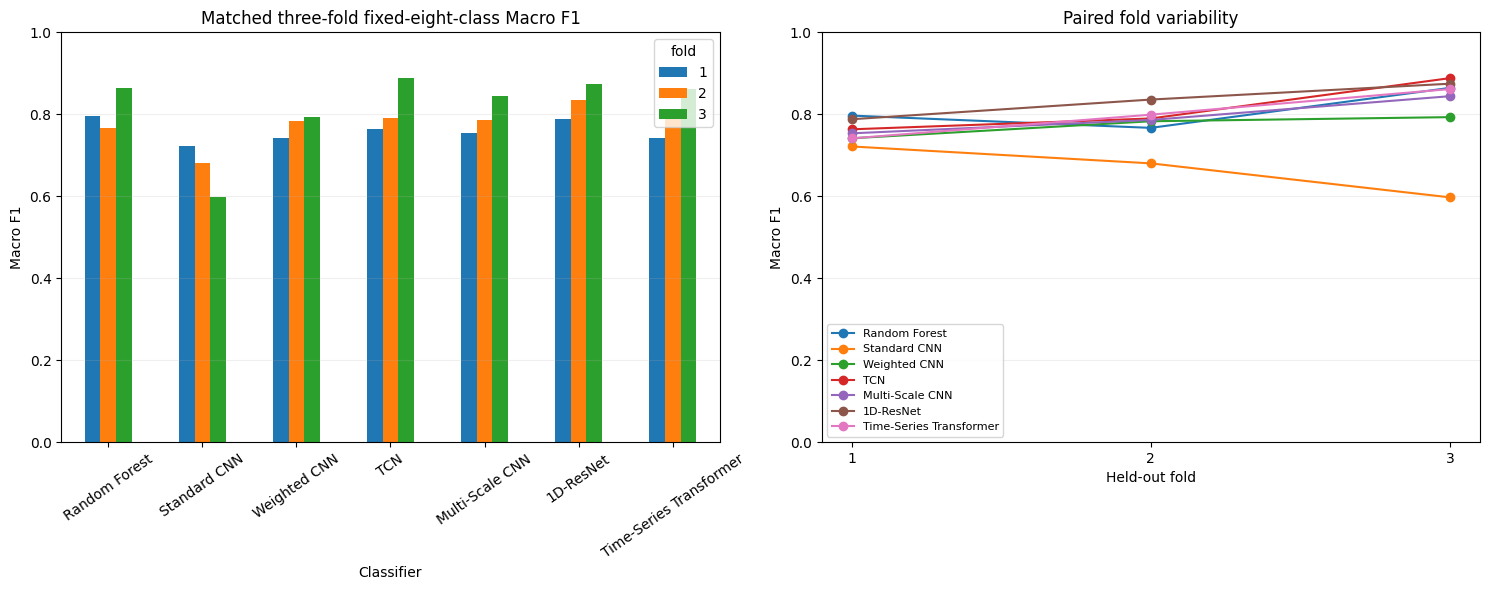

In [8]:
# ============== 07. Compare Seven Models Across Held-Out Folds ==============

# ------------ 1. Pivot seven model scores across the three folds ------------
wide=fold_results.pivot(index="model",columns="fold",values="macro_f1"
).reindex(MODEL_NAMES)

# -------------- 2. Review the exact original fold-level results --------------
display(wide.round(4))

# ----------------- 3. Create matched fold-comparison figures -----------------
fig,axes=plt.subplots(1,2,figsize=(15,6))

# --------------- 4. Compare models on identical Macro F1 axes ---------------
wide.plot(kind="bar",ax=axes[0],rot=35,ylim=(0,1))
axes[0].set(title="Matched three-fold fixed-eight-class Macro F1",
            xlabel="Classifier",ylabel="Macro F1")

# ------------- 5. Trace each model across held-out participants -------------
for model in MODEL_NAMES:
    rows=fold_results[fold_results["model"]==model].sort_values("fold")
    axes[1].plot(rows["fold"],rows["macro_f1"],marker="o",label=model)
axes[1].set(title="Paired fold variability",xlabel="Held-out fold",
            ylabel="Macro F1",ylim=(0,1),xticks=[1,2,3])
axes[1].legend(fontsize=8)
for ax in axes: ax.grid(axis="y",alpha=0.2)

# ----------------- 6. Preserve the original comparison plots -----------------
fig.tight_layout()
plt.show()

**08. Class-Level F1, Shuffling, Stair Activities and Confusion Matrices**

The primary minority-class questions concern Shuffling, Stairs ascending and Stairs descending. A class-level table must show support alongside precision, recall and F1. Pooled out-of-fold metrics are calculated across correlated windows and should be interpreted as descriptive rather than independent person-level outcomes. The confusion matrices show which activities models confuse, retaining the same original class-code order in all seven figures.

**Rare-class evidence:** Shuffling has 219 original Validation windows; the pooled F1 values differ markedly between models. Aggregate accuracy cannot substitute for rare-class performance.

,model,class_code,activity,support,precision,recall,f1
0,Random Forest,1,Walking,3591,0.9272,0.9510,0.9390
1,Random Forest,2,Running,1028,0.9836,0.9903,0.9869
2,Random Forest,3,Shuffling,219,0.4756,0.5342,0.5032
3,Random Forest,4,Stairs ascending,192,0.7310,0.5521,0.6291
4,Random Forest,5,Stairs descending,182,0.7031,0.4945,0.5806
5,Random Forest,6,Standing,2227,0.9382,0.9618,0.9499
6,Random Forest,7,Sitting,5599,0.9969,0.9791,0.9879
7,Random Forest,8,Lying,1163,0.9831,0.9991,0.9910
8,Standard CNN,1,Walking,3591,0.8971,0.9563,0.9257
9,Standard CNN,2,Running,1028,0.9873,0.9844,0.9859


,model,activity,support,recall,f1
2,Random Forest,Shuffling,219,0.5342,0.5032
3,Random Forest,Stairs ascending,192,0.5521,0.6291
4,Random Forest,Stairs descending,182,0.4945,0.5806
10,Standard CNN,Shuffling,219,0.0000,0.0000
11,Standard CNN,Stairs ascending,192,0.1198,0.2009
12,Standard CNN,Stairs descending,182,0.2033,0.3318
18,Weighted CNN,Shuffling,219,0.1050,0.1390
19,Weighted CNN,Stairs ascending,192,0.8073,0.5720
20,Weighted CNN,Stairs descending,182,0.6374,0.6170
26,TCN,Shuffling,219,0.3973,0.3392


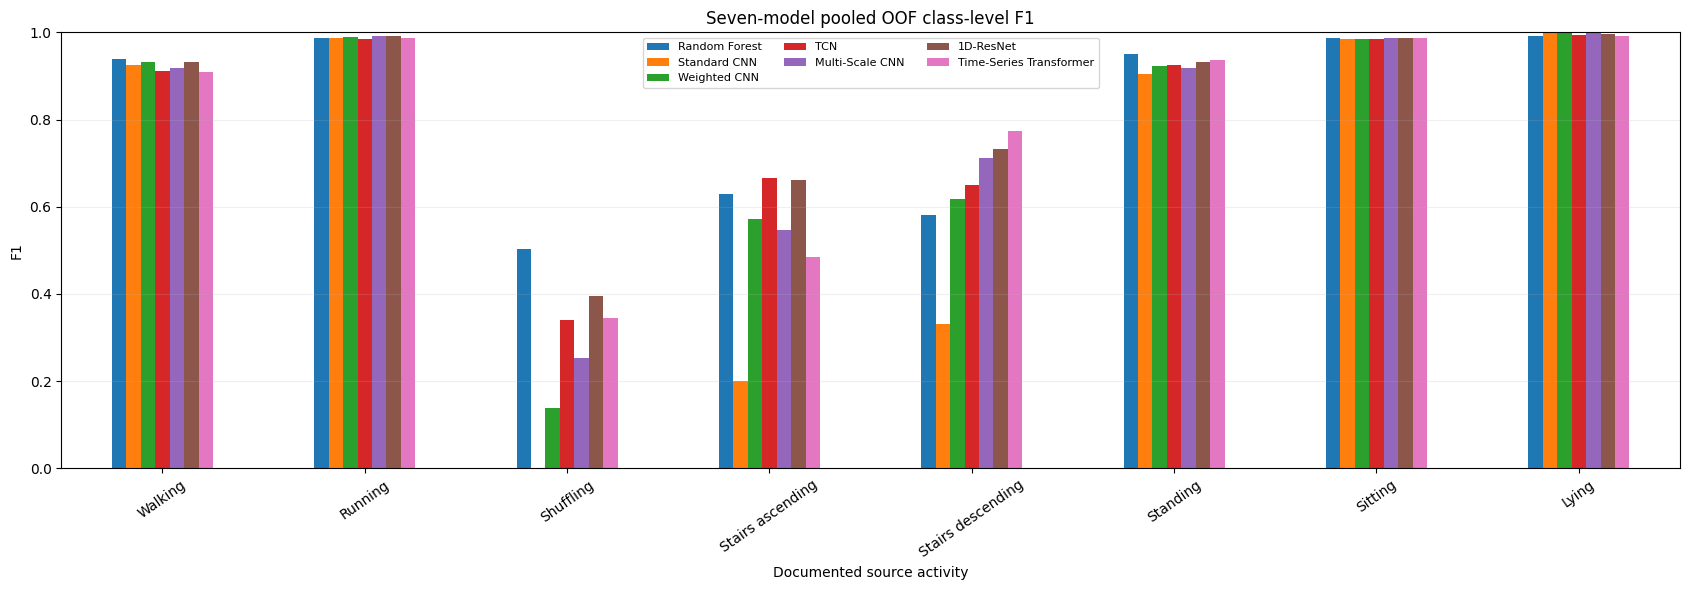

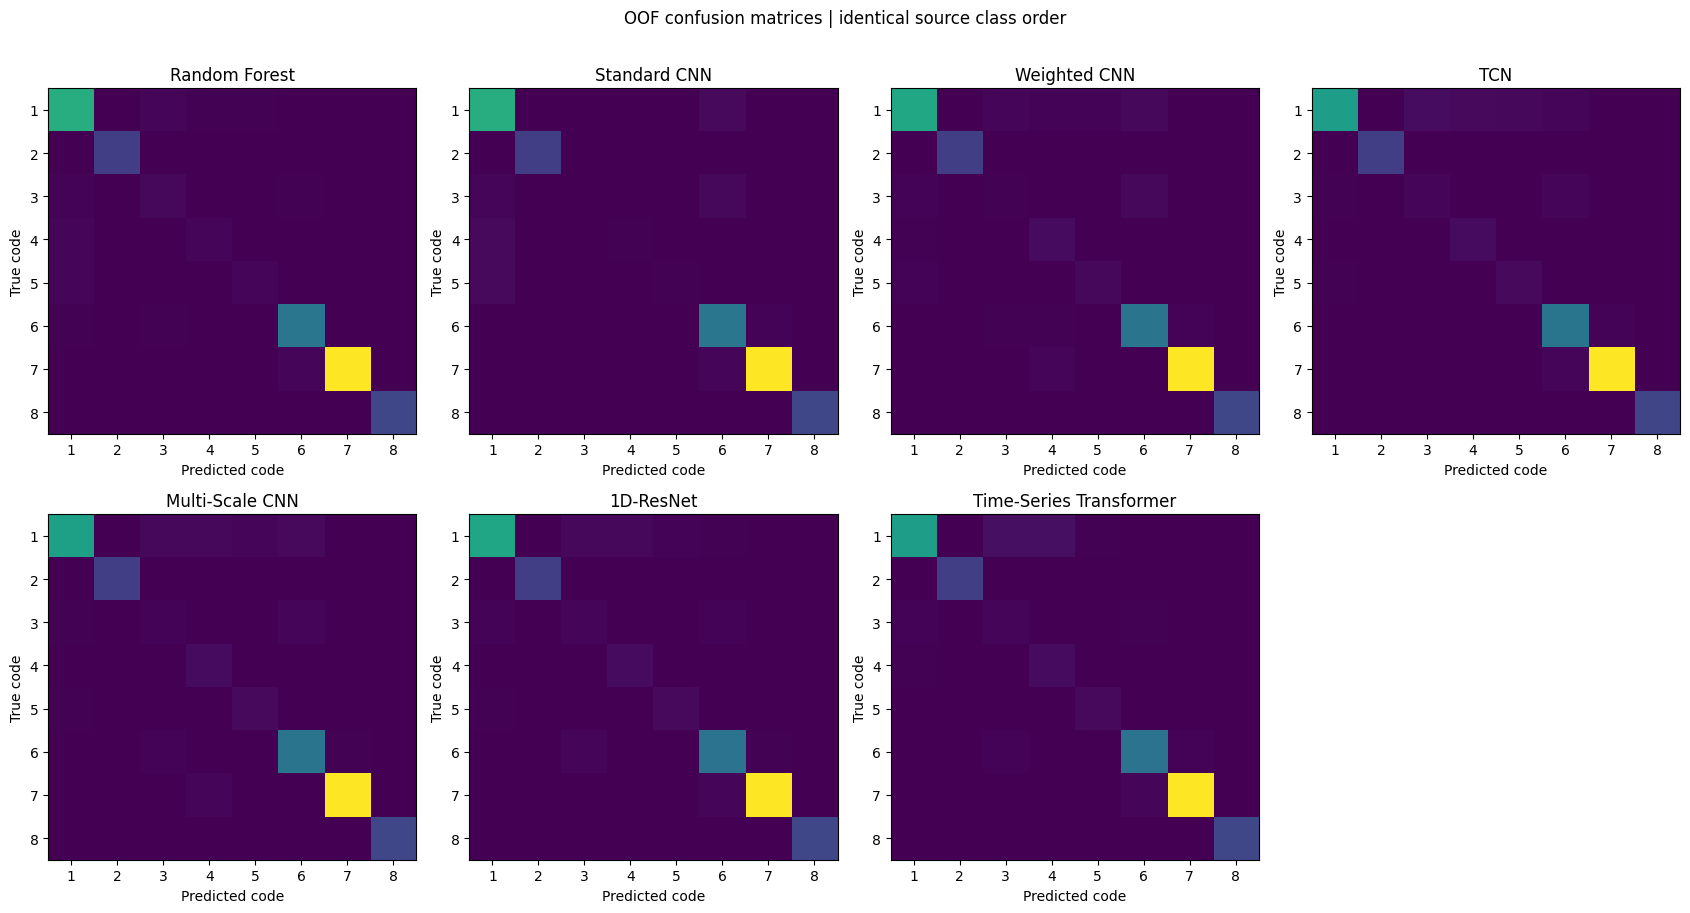

In [9]:
# =============== 08. Review Rare Classes and Confusion Errors ===============

# --------------- 1. Use documented HARTH activity class names ---------------
class_results["activity"]=class_results["class_code"].map(ACTIVITY_NAMES)

# ---------------- 2. Report precision, recall, F1 and support ----------------
display(class_results[[
    "model","class_code","activity","support","precision","recall","f1"
]].round(4))

# ---------------- 3. Isolate Shuffling and both stair classes ----------------
minority=class_results[class_results["class_code"].isin([3,4,5])]

# -------------- 4. Display observed minority-class performance --------------
display(minority[["model","activity","support","recall","f1"]].round(4))

# -------------- 5. Align activity-level F1 across seven models --------------
class_pivot=class_results.pivot(index="activity",columns="model",values="f1")
class_pivot=class_pivot.reindex([ACTIVITY_NAMES[c] for c in CLASSES])
class_pivot=class_pivot.reindex(columns=MODEL_NAMES)

# ---------------- 6. Plot pooled out-of-fold activity scores ----------------
fig,ax=plt.subplots(figsize=(17,6))
class_pivot.plot(kind="bar",ax=ax,rot=35,ylim=(0,1))
ax.set(title="Seven-model pooled OOF class-level F1",
       xlabel="Documented source activity",ylabel="F1")
ax.legend(fontsize=8,ncol=3)
ax.grid(axis="y",alpha=0.2)
fig.tight_layout()
plt.show()

# ------------ 7. Create identical seven-model confusion matrices ------------
fig,axes=plt.subplots(2,4,figsize=(17,9))

# ----------- 8. Inspect original class-level prediction confusions -----------
for ax,name in zip(axes.flat,MODEL_NAMES):
    matrix=confusion[name]
    ax.imshow(matrix,interpolation="nearest",aspect="auto")
    ax.set(title=name,xlabel="Predicted code",ylabel="True code")
    ax.set_xticks(range(8),CLASSES)
    ax.set_yticks(range(8),CLASSES)
for ax in list(axes.flat)[len(MODEL_NAMES):]:
    ax.axis("off")
fig.suptitle("OOF confusion matrices | identical source class order",y=1.01)
fig.tight_layout()
plt.show()

**09. Participant-Level Fairness of Comparison and Model-Error Variability**

One model score per held-out person reduces the tendency to mistake thousands of overlapping windows for thousands of independent subjects. Our fixed-task Macro F1 includes all eight task codes for each individual, whereas an observed-class F1 only includes activities actually labelled for that participant. Both interpretations matter and must not be conflated. This is an exploratory robustness comparison, not a demographic fairness analysis or a statistical-significance claim.

model,Random Forest,Standard CNN,Weighted CNN,TCN,Multi-Scale CNN,1D-ResNet,Time-Series Transformer
subject_id,,,,,,,
S006,0.6826,0.4580,0.6860,0.7905,0.7214,0.7608,0.7326
S008,0.4254,0.3397,0.3561,0.5138,0.4542,0.5505,0.5578
S009,0.3261,0.2319,0.3460,0.4180,0.4268,0.4100,0.4070
S010,0.4445,0.3540,0.6317,0.5352,0.5428,0.6324,0.5743
S012,0.8718,0.5842,0.7733,0.9325,0.9114,0.9173,0.6181
S013,0.6790,0.5508,0.7424,0.8082,0.8487,0.8677,0.7426
S014,0.8071,0.5887,0.7996,0.7984,0.7315,0.7690,0.8315
S015,0.7156,0.6527,0.7412,0.7410,0.7866,0.8136,0.6370
S016,0.7160,0.6119,0.6119,0.7953,0.7845,0.8592,0.7982


Participants per model: {'Random Forest': 29, 'Standard CNN': 29, 'Weighted CNN': 29, 'TCN': 29, 'Multi-Scale CNN': 29, '1D-ResNet': 29, 'Time-Series Transformer': 29}


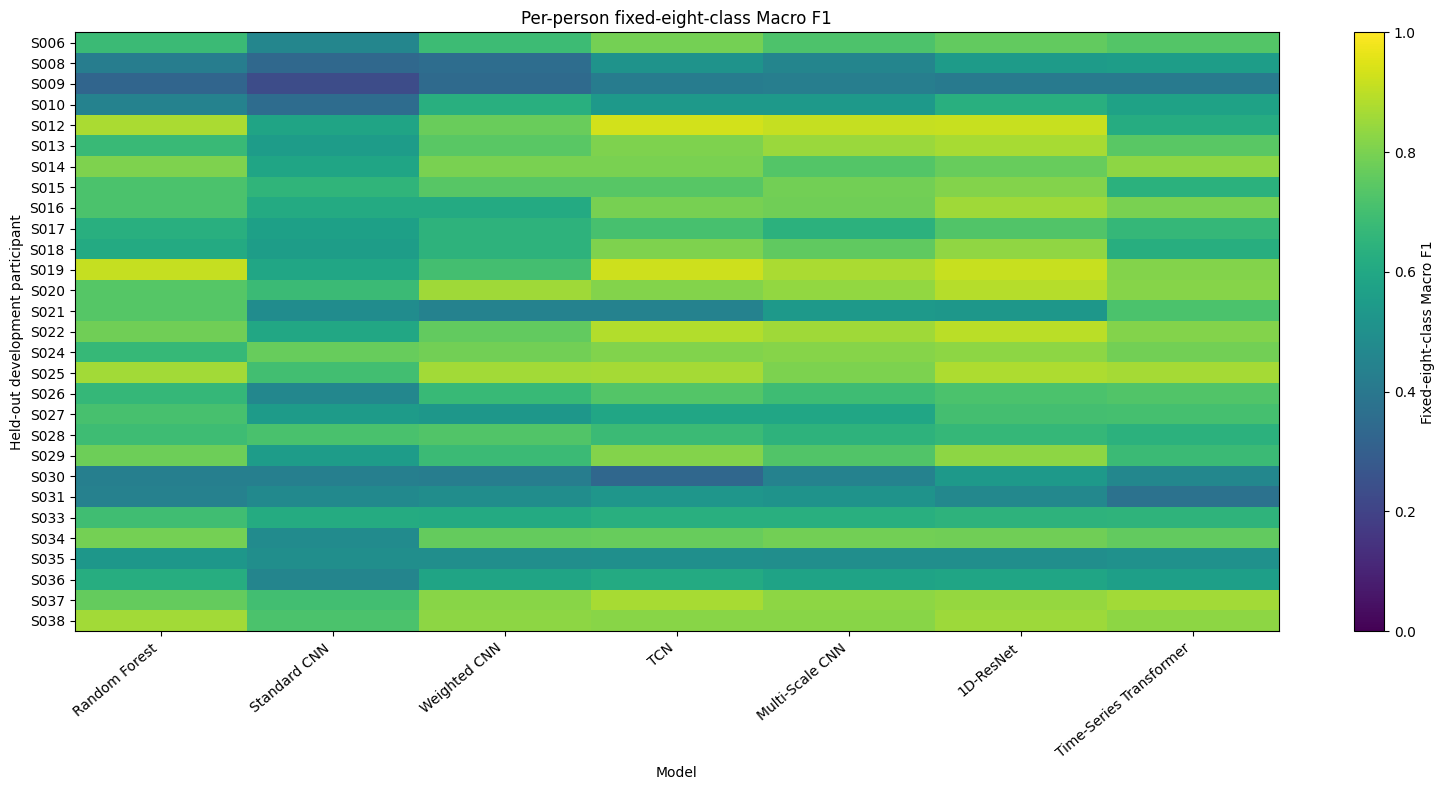

In [10]:
# ================ 09. Audit Scores by Independent Participant ================

# -------------- 1. Align fixed-task F1 by participant and model --------------
individual=subject_results.pivot(
    index="subject_id",columns="model",values="macro_f1_fixed_task"
).reindex(index=DEVELOPMENT_SUBJECTS,columns=MODEL_NAMES)

# ----------- 2. Review twenty-nine independent person-level scores -----------
display(individual.round(4))

# --------------- 3. Reject missing participant/model outcomes ---------------
assert individual.notna().all().all()
print("Participants per model:",individual.notna().sum().to_dict())

# ----------- 4. Construct original participant-level score heatmap -----------
fig,ax=plt.subplots(figsize=(16,8))

# ----------- 5. Show person-to-person model performance variation -----------
im=ax.imshow(individual.to_numpy(),aspect="auto",vmin=0,vmax=1)
ax.set_xticks(range(len(MODEL_NAMES)),MODEL_NAMES,rotation=40,ha="right")
ax.set_yticks(range(len(DEVELOPMENT_SUBJECTS)),DEVELOPMENT_SUBJECTS)
ax.set(title="Per-person fixed-eight-class Macro F1",xlabel="Model",
       ylabel="Held-out development participant")

# --------------- 6. Label the genuine zero-to-one score range ---------------
fig.colorbar(im,ax=ax,label="Fixed-eight-class Macro F1")
fig.tight_layout()
plt.show()

**10. Model Complexity, Training Time and Experimental Reproducibility**

Parameter count is meaningful for the six neural architectures, while Random Forest is characterised by its number of trees and training time, not an equivalent neural parameter count. Training time includes batch preparation and optimisation but not public-source download or preprocessing; Validation inference time depends on the local hardware. Caches exist only for successful fold/model runs and are fingerprinted to source arrays and code. They hold predictions, **not reloadable model weights**; a future inference release needs separate final-model training and saved weights in Stage 26.

,model,total_train_s,mean_train_s_per_fold,total_validation_inference_s,trainable_parameters
0,1D-ResNet,33.022,11.007,0.130,91176
1,Multi-Scale CNN,8.793,2.931,0.150,16488
2,Random Forest,13.339,4.446,0.180,0
3,Standard CNN,7.523,2.508,0.117,12392
4,TCN,9.383,3.128,0.134,38056
5,Time-Series Transformer,13.288,4.429,0.392,38744
6,Weighted CNN,4.273,1.424,0.048,12392


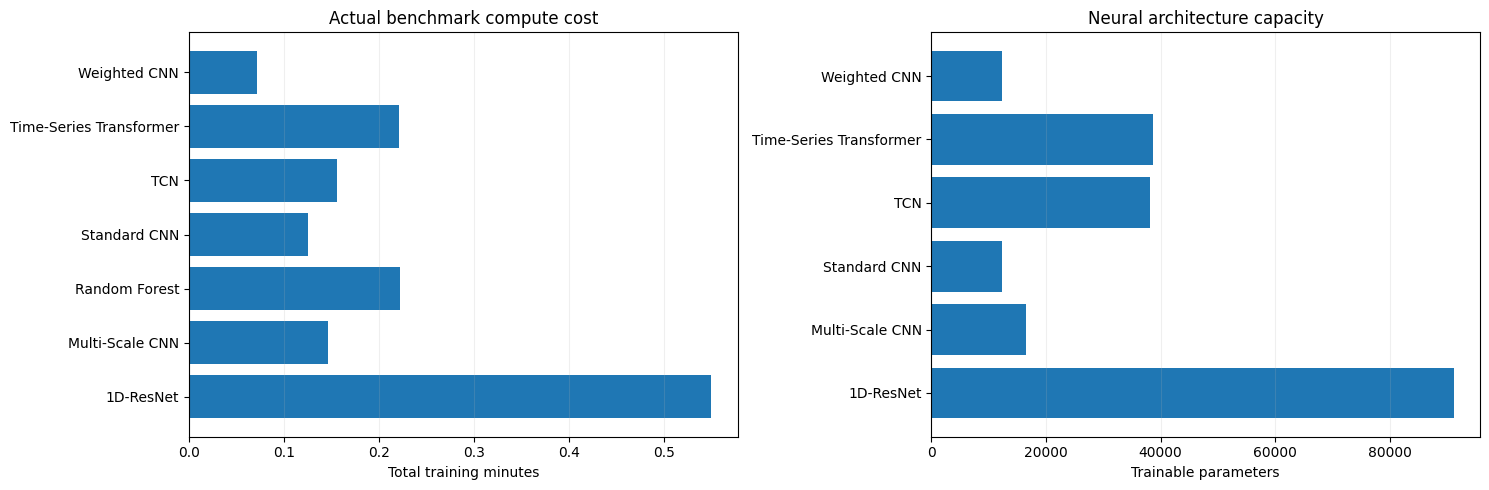

Stored source fingerprint: 672d4109727a20ea30f2557f6b405445fce86be1898a58851fa976f8ed8bf297
Model scores reproduced from actual saved held-out predictions: YES


In [11]:
# ============== 10. Inspect Model Complexity and Hardware Costs ==============

# ------------ 1. Aggregate observed training time and model cost ------------
costs=fold_results.groupby("model",as_index=False).agg(
    total_train_s=("train_seconds","sum"),
    mean_train_s_per_fold=("train_seconds","mean"),
    total_validation_inference_s=("validation_inference_seconds","sum"),
    trainable_parameters=("trainable_parameters","max"),
)

# -------------- 2. Report original hardware-dependent runtimes --------------
display(costs.round(3))

# ---------------- 3. Prepare training-cost and capacity plots ----------------
fig,axes=plt.subplots(1,2,figsize=(15,5))

# ---------------- 4. Compare measured training time by model ----------------
axes[0].barh(costs["model"],costs["total_train_s"]/60)
axes[0].set(xlabel="Total training minutes",title="Actual benchmark compute cost")

# ------------- 5. Separate neural parameter counts from RF trees -------------
neural=costs[costs["model"]!="Random Forest"]

# ----------------- 6. Plot trainable neural parameter counts -----------------
axes[1].barh(neural["model"],neural["trainable_parameters"])
axes[1].set(xlabel="Trainable parameters",title="Neural architecture capacity")
for ax in axes: ax.grid(axis="x",alpha=0.2)
fig.tight_layout()
plt.show()

# ---------------- 7. Preserve experiment and cache provenance ----------------
print("Stored source fingerprint:",plan["fingerprint"])
print("Model scores reproduced from actual saved held-out predictions: YES")

**11. Research Interpretation and Decision Criteria for Stage 24**

This notebook supplies evidence for an architecture shortlist but not a final model choice or universal ranking. Strong development Macro F1 alone is insufficient: minority-class recall, consistency between folds and participants, training cost and stability across random seeds also matter. Stage 24 will retest a justified shortlist using multiple seeds and carefully isolated loss/imbalance interventions such as Focal Loss. **Any later selection must use Development only**, with S023/S032 held out from further model development.

In [12]:
# ============= 11. Interpret Benchmark Evidence and Limitations =============

# ----------- 1. Add minority-class F1 to the model evidence table -----------
shuffling=class_results[class_results["class_code"]==3][["model","f1"]].rename(
    columns={"f1":"shuffling_pooled_f1"}
)

# -------------- 2. Align fold variation, class F1 and run time --------------
decision=summary.merge(shuffling,on="model",validate="one_to_one")

# -------------- 3. Present Development-only shortlist evidence --------------
display(decision.sort_values("macro_f1_mean",ascending=False)[[
    "model","macro_f1_mean","macro_f1_sd",
    "balanced_accuracy_mean","shuffling_pooled_f1",
    "total_train_seconds","parameters"
]].round(4))

# ------------ 4. Document limitations and untested generalisation ------------
limitations=pd.DataFrame([
    {"issue":"Development-only model comparison","restriction":"No independent Test claim"},
    {"issue":"500-cap label-blind sampling","restriction":"Not full-data optimum or class-balanced task"},
    {"issue":"One seed and three folds","restriction":"Cannot claim strong stability or significance"},
    {"issue":"Different architecture sizes and representations","restriction":"Not isolated causal architecture advantage"},
    {"issue":"Window overlap","restriction":"No independence of window-level observations"},
    {"issue":"Original Test exploratory history","restriction":"S023/S032 not preregistered-unseen"},
])

# ---------- 5. Distinguish observed scores from causal conclusions ----------
display(limitations)

,model,macro_f1_mean,macro_f1_sd,balanced_accuracy_mean,shuffling_pooled_f1,total_train_seconds,parameters
0,1D-ResNet,0.8328,0.0435,0.8688,0.3962,33.0217,91176
4,TCN,0.8138,0.0658,0.8575,0.3392,9.3827,38056
2,Random Forest,0.8094,0.0500,0.8063,0.5032,13.3388,0
5,Time-Series Transformer,0.8006,0.0602,0.8552,0.3444,13.2878,38744
1,Multi-Scale CNN,0.7946,0.0459,0.8392,0.2522,8.7932,16488
6,Weighted CNN,0.7725,0.0274,0.8022,0.1390,4.2729,12392
3,Standard CNN,0.6664,0.0633,0.6575,0.0000,7.5230,12392


,issue,restriction
0,Development-only model comparison,No independent Test claim
1,500-cap label-blind sampling,Not full-data optimum or class-balanced task
2,One seed and three folds,Cannot claim strong stability or significance
3,Different architecture sizes and representations,Not isolated causal architecture advantage
4,Window overlap,No independence of window-level observations
5,Original Test exploratory history,S023/S032 not preregistered-unseen


**12. Final Source-Provenance and Scientific Quality Gate**

This gate rejects incomplete jobs, missing source-window predictions, duplicated held-out participants per model, non-finite metrics and any inclusion of protected Test people. A passing result means the seven *configured* models were actually evaluated on identical source rows using a subject-disjoint Development protocol. It does **not** prove external generalisation, superior performance on unseen settings, or final Test validation. Stage 24 will address multi-seed stability and class imbalance using the results generated here.

**Evidence boundary:** These three group folds and one seed do not establish external validation, statistical significance or an isolated architectural advantage; S023 and S032 were inspected in early historical stages.

In [13]:
# ============== 12. Scientific Provenance and Completeness Gate ==============

# ---------- 1. Require all seven models across three complete folds ----------
assert len(jobs)==len(MODEL_NAMES)*FOLDS==21
assert len(fold_results)==21

# ------------- 2. Verify one source-matched prediction per model -------------
assert len(predictions)==len(X)*len(MODEL_NAMES)
assert len(subject_results)==len(DEVELOPMENT_SUBJECTS)*len(MODEL_NAMES)
assert len(class_results)==len(MODEL_NAMES)*len(CLASSES)

# ------------- 3. Protect label, row and participant provenance -------------
for name,table in predictions.groupby("model"):
    assert len(table)==len(X) and table["source_row"].is_unique
    assert not(set(table["subject_id"])&RESERVED_TEST)
    np.testing.assert_array_equal(
        table.sort_values("source_row")["true_label"].to_numpy(),y
    )

# ---------- 4. Validate the range of reported classification scores ----------
assert fold_results["macro_f1"].between(0,1).all()
assert class_results["f1"].between(0,1).all()

# ------------ 5. Require complete eight-class confusion matrices ------------
assert all(confusion[name].shape==(8,8) for name in MODEL_NAMES)

print(""+"="*70)

# ----------- 6. Report the verified experiment completion boundary -----------
print("STAGE 23 | SEVEN-MODEL MATCHED GROUPED DEVELOPMENT BENCHMARK")
print("="*70)
print("Seven model families evaluated:",len(MODEL_NAMES))
print("Complete model/fold jobs:",len(jobs))
print("Independent Development participants:",len(DEVELOPMENT_SUBJECTS))
print("Validation source rows per model:",len(X))
print("Fixed eight-class metrics: PASSED")
print("Matched source-row and subject-fold identities: PASSED")
print("All seven actual training/evaluation runs: PASSED")
print("Original protected Test participants accessed: NO")
print("-"*70)

# ----------- 7. Confirm the passing Development-only quality gate -----------
print("Stage 23 scientific quality gate: PASSED")
print("Independent full-dataset generalisation established: NO")
print("Final model selection performed: NO")
print("Next stage: Stage 24 - Multi-Seed and Class-Imbalance Robustness")
print("="*70)

STAGE 23 | SEVEN-MODEL MATCHED GROUPED DEVELOPMENT BENCHMARK
Seven model families evaluated: 7
Complete model/fold jobs: 21
Independent Development participants: 29
Validation source rows per model: 14201
Fixed eight-class metrics: PASSED
Matched source-row and subject-fold identities: PASSED
All seven actual training/evaluation runs: PASSED
Original protected Test participants accessed: NO
----------------------------------------------------------------------
Stage 23 scientific quality gate: PASSED
Independent full-dataset generalisation established: NO
Final model selection performed: NO
Next stage: Stage 24 - Multi-Seed and Class-Imbalance Robustness
